<a href="https://colab.research.google.com/github/muhamadzakiabdulkhair-del/pm-turi4-clustering/blob/main/PM_Pertemuan9_Praktikum_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 4 (TuRi 4): Clustering dengan K-Means
Nama: Muhamad Zaki Abdul Khair | NIM: 2488010053 | Pertemuan 9

###Langkah 1 — Menyiapkan data & scaling (wajib).

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

def grup(n, usia, pendapatan, skor):
    return pd.DataFrame({
        'usia': np.random.normal(*usia, n),
        'pendapatan': np.random.normal(*pendapatan, n),
        'skor_belanja': np.random.normal(*skor, n)})

df = pd.concat([
    grup(70, (23, 3), (4_000_000, 800_000), (80, 8)),
    grup(70, (45, 5), (12_000_000, 1_500_000), (70, 8)),
    grup(60, (55, 5), (6_000_000, 1_000_000), (25, 8))], ignore_index=True)

df['usia'] = df['usia'].clip(17, 70).round()
df['pendapatan'] = df['pendapatan'].clip(1_000_000).round(-3)
df['skor_belanja'] = df['skor_belanja'].clip(1, 100).round()

FITUR = ['usia', 'pendapatan', 'skor_belanja']
X_scaled = StandardScaler().fit_transform(df[FITUR])


###Langkah 2 — Metode Elbow menentukan K.


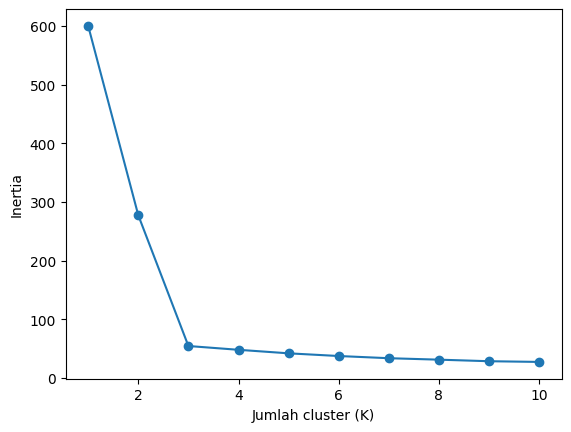

In [ ]:
from sklearn.cluster import KMeans

inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.plot(range(1, 11), inertias, marker='o')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Inertia')
plt.show()

###Langkah 3 — Menjalankan K-Means (K=3).


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts())


cluster
2    70
0    70
1    60
Name: count, dtype: int64


###Langkah 4 — Evaluasi silhouette score.

In [ ]:
from sklearn.metrics import silhouette_score
print(silhouette_score(X_scaled, df['cluster']))


0.7441664320861693


###Langkah 5 — Interpretasi: profil rata-rata tiap cluster.

In [ ]:
profil = df.groupby('cluster')[['usia','pendapatan',
    'skor_belanja']].mean().round(1)
print(profil)   # beri nama tiap cluster berdasarkan profil


         usia  pendapatan  skor_belanja
cluster                                
0        44.8  12104600.0          71.0
1        55.0   5732583.3          25.0
2        22.6   3973271.4          80.8


##Latihan Mandiri

###Langkah 6 - Jalankan K-Means K=5; bandingkan silhouette score dengan K=3.


In [ ]:
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
label5 = km5.fit_predict(X_scaled)
skor_k5 = silhouette_score(X_scaled, label5)

print(f"Silhouette K=3: {skor_k3:.3f}")
print(f"Silhouette K=5: {skor_k5:.3f}")

Silhouette K=3: 0.744
Silhouette K=5: 0.446


###Langkah 7 K-Means tanpa scaling (K=3); bandingkan silhouette-nya. Apa kesimpulannya?

In [ ]:
X_mentah = df[FITUR]
km_ns = KMeans(n_clusters=3, random_state=42, n_init=10)
label_ns = km_ns.fit_predict(X_mentah)
skor_ns = silhouette_score(X_mentah, label_ns)

print(f"Silhouette dengan scaling : {skor_k3:.3f}")
print(f"Silhouette tanpa scaling  : {skor_ns:.3f}")

Silhouette dengan scaling : 0.744
Silhouette tanpa scaling  : 0.652


Kesimpulan:
Silhouette tanpa scaling (0.652) lebih rendah daripada dengan scaling
(0.744). Tanpa scaling, pendapatan yang bernilai jutaan mendominasi
perhitungan jarak, sedangkan usia dan skor belanja hampir tidak
berpengaruh. Jadi scaling wajib dilakukan sebelum K-Means.

###Langkah 8 Buat scatter plot cluster pada fitur usia (x) vs skor_belanja (y)

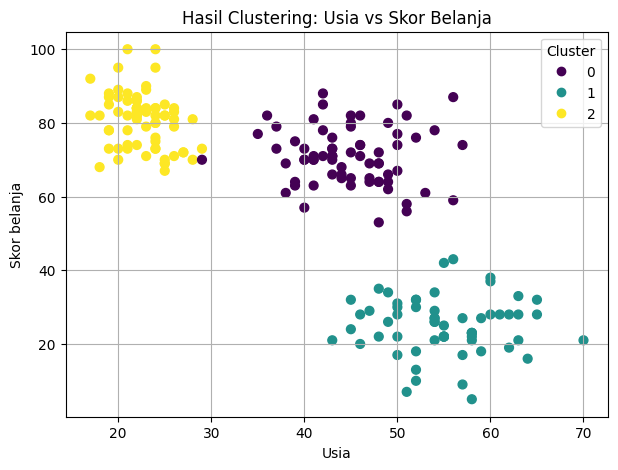

In [ ]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(df['usia'], df['skor_belanja'],
                      c=df['cluster'], cmap='viridis', s=40)
plt.title('Hasil Clustering: Usia vs Skor Belanja')
plt.xlabel('Usia')
plt.ylabel('Skor belanja')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(True)
plt.show()

##Refleksi

**1. Bagaimana K-Means menemukan kelompok tanpa label?**
K-Means tidak memakai label, hanya kemiripan berdasarkan jarak.
Pertama, K centroid diletakkan secara acak. Kedua, tiap titik masuk
ke centroid terdekat. Ketiga, centroid dihitung ulang sebagai
rata-rata anggotanya. Langkah kedua dan ketiga diulang sampai centroid
tidak berpindah lagi (konvergen). Titik yang berdekatan akhirnya
berada dalam cluster yang sama.

**2. Mengapa metode Elbow menunjukkan siku di K=3 pada data ini?**
Karena data ini memang terdiri dari 3 kelompok alami. Dari K=1 ke K=3,
inertia turun sangat besar (sekitar 600 menjadi 54) karena tiap
cluster baru memisahkan kelompok yang benar-benar berbeda. Setelah
K=3, penurunannya kecil (54 menjadi 48 dan seterusnya) karena
tambahan cluster hanya memecah kelompok yang sudah rapat. Titik
tekukan itu adalah siku.

**3. Mengapa scaling penting, dan apa dampaknya bila dilewatkan?**
K-Means berbasis jarak. Fitur berangka besar (pendapatan, jutaan)
mendominasi jarak, sedangkan fitur berangka kecil (usia, skor belanja)
hampir diabaikan. Tanpa scaling, silhouette turun dari 0.744 menjadi
0.652 dan hasil clustering hanya mencerminkan pendapatan. Scaling
menyamakan skala sehingga ketiga fitur berkontribusi seimbang.